# Example walkthrough: real study results (standalone)

This notebook is **fully standalone** -- it does not import anything from this repository's
`src/` folder. It only reads the small CSV files bundled in `notebooks/results_data/`.

**What's in `results_data/`:** aggregate, de-identified summary statistics produced by the
completed no-ADHD nested-CV analysis (final outer-test metrics, SHAP values, permutation
importances, a Spearman correlation matrix) -- the same numbers that appear in the paper's own
tables and figures. **This is not participant-level data.** No raw survey responses are included
anywhere in this repository; see [`data/README.md`](../data/README.md) for how to request the
real cohort data (IRB-gated) if you want to re-run the pipeline in `src/` yourself.

Run all cells top to bottom; nothing outside this `notebooks/` folder is required.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path("results_data")
pd.set_option("display.max_colwidth", 60)

## Figure style (inlined from `src/utils/figure_style.py`)

Copied here, not imported, so this notebook has zero dependency on the rest of the repo.
Sets a Times-like typeface (STIX General, shipped with Matplotlib) matching the paper's figures.

In [2]:
import matplotlib
from matplotlib import font_manager

def use_times_style() -> None:
    """Inlined from src/utils/figure_style.py -- sets the paper's Times-like face."""
    stix_dir = Path(matplotlib.get_data_path()) / "fonts" / "ttf"
    for name in ("STIXGeneral.ttf", "STIXGeneralBol.ttf", "STIXGeneralItalic.ttf", "STIXGeneralBolIta.ttf"):
        font_manager.fontManager.addfont(str(stix_dir / name))
    plt.rcParams.update({
        "font.family": "STIXGeneral",
        "mathtext.fontset": "stix",
        "axes.spines.top": False,
        "axes.spines.right": False,
    })

use_times_style()

## 1. Final locked-in recipe per target

Each target (ODD, DICCD) was searched **independently** through a 4-stage nested-CV comparison
(Model -> Sampler -> Loss -> Hyperparameter). The two targets converged on genuinely different
final recipes -- DICCD was *not* assumed to share ODD's. Values below are transcribed from
[`configs/recipes.yaml`](../configs/recipes.yaml) in this repository (not re-derived here).

In [3]:
recipe = pd.DataFrame([
    {"item": "Sampler (train-only)", "ODD": "ADASYN (1:1)", "DICCD": "None (no resampling)"},
    {"item": "Loss", "ODD": "Focal (gamma=2.0)", "DICCD": "BCE (unweighted)"},
    {"item": "criterion", "ODD": "gini", "DICCD": "entropy"},
    {"item": "min_samples_leaf", "ODD": "1", "DICCD": "1"},
    {"item": "max_depth", "ODD": "None (unrestricted)", "DICCD": "12"},
    {"item": "max_features", "ODD": "sqrt", "DICCD": "sqrt"},
]).set_index("item")
recipe

,ODD,DICCD
item,,
Sampler (train-only),ADASYN (1:1),None (no resampling)
Loss,Focal (gamma=2.0),BCE (unweighted)
criterion,gini,entropy
min_samples_leaf,1,1
max_depth,None (unrestricted),12
max_features,sqrt,sqrt


## 2. Final outer-test performance (real results)

`locked_recipe_outer_metrics_{odd,diccd}.csv` holds the **actual per-outer-fold** test
performance (5 folds x 3 feature sets) from the completed nested-CV run, using each target's
own locked-in recipe above. Nothing here is synthetic; every number below is read directly
from these two files.

In [4]:
odd_metrics = pd.read_csv(RESULTS_DIR / "locked_recipe_outer_metrics_odd.csv")
diccd_metrics = pd.read_csv(RESULTS_DIR / "locked_recipe_outer_metrics_diccd.csv")
all_metrics = pd.concat([odd_metrics, diccd_metrics], ignore_index=True)
all_metrics.head()

,target,feature_set,outer_fold,threshold_inner_oof,Accuracy,Sensitivity,Specificity,Precision,Recall,F1-score,AUC Score
0,ODD,Combined,1,0.120,0.796160,0.777778,0.797192,0.177215,0.777778,0.288660,0.878055
1,ODD,Combined,2,0.118,0.790251,0.777778,0.790952,0.172840,0.777778,0.282828,0.855629
2,ODD,Combined,3,0.120,0.786982,0.800000,0.786271,0.169697,0.800000,0.280000,0.881079
3,ODD,Combined,4,0.182,0.884615,0.600000,0.900156,0.247059,0.600000,0.350000,0.871250
4,ODD,Combined,5,0.166,0.850592,0.600000,0.864275,0.194444,0.600000,0.293706,0.868086


In [5]:
summary = (
    all_metrics[all_metrics["feature_set"] == "Combined"]
    .groupby("target")[["Accuracy", "Specificity", "Recall", "F1-score", "AUC Score"]]
    .agg(["mean", "std"])
)
summary.columns = [f"{m}_{s}" for m, s in summary.columns]
summary = summary.round(3)
print("Combined feature set, mean +/- SD across the 5 outer-test folds:")
summary

Combined feature set, mean +/- SD across the 5 outer-test folds:


,Accuracy_mean,Accuracy_std,Specificity_mean,Specificity_std,Recall_mean,Recall_std,F1-score_mean,F1-score_std,AUC Score_mean,AUC Score_std
target,,,,,,,,,,
DICCD,0.817,0.031,0.821,0.034,0.752,0.096,0.326,0.050,0.871,0.041
ODD,0.822,0.044,0.828,0.051,0.711,0.102,0.299,0.029,0.871,0.010


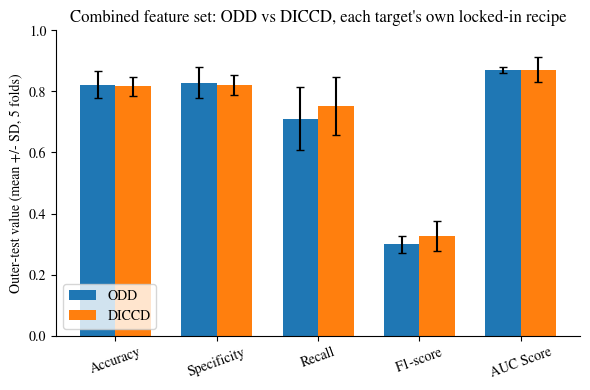

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
metrics = ["Accuracy", "Specificity", "Recall", "F1-score", "AUC Score"]
x = np.arange(len(metrics))
width = 0.35
for i, target in enumerate(["ODD", "DICCD"]):
    means = [summary.loc[target, f"{m}_mean"] for m in metrics]
    sds = [summary.loc[target, f"{m}_std"] for m in metrics]
    ax.bar(x + (i - 0.5) * width, means, width, yerr=sds, capsize=3, label=target)
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=20)
ax.set_ylabel("Outer-test value (mean +/- SD, 5 folds)")
ax.set_title("Combined feature set: ODD vs DICCD, each target's own locked-in recipe")
ax.legend()
ax.set_ylim(0, 1.0)
fig.tight_layout()
plt.show()

## 3. SHAP importance -- top 10, Combined feature set (real results)

ADHD-symptom-score was removed from the feature set entirely before this was computed (it is
not a candidate feature, not merely a low-ranked one). With it gone, Smartphone Addiction
becomes the top-ranked feature for **both** targets.

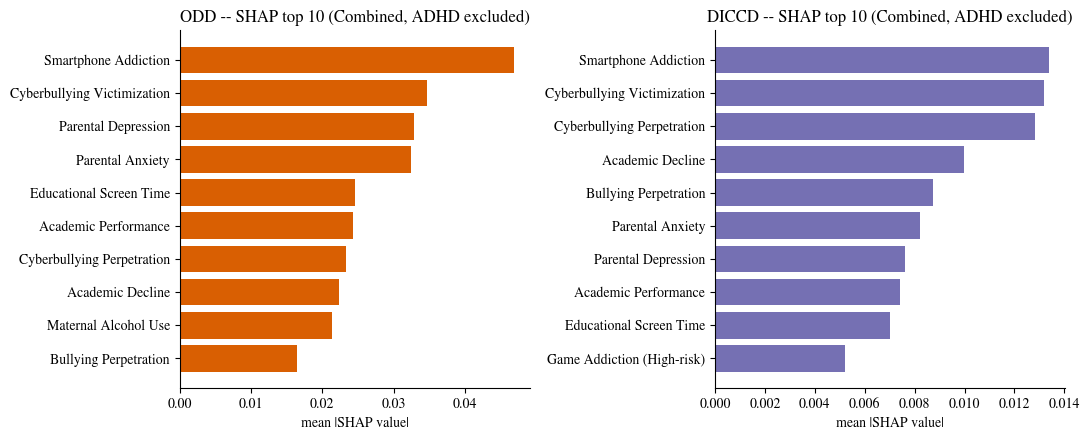

,label,mean_abs_shap
0,Smartphone Addiction,0.046826
1,Cyberbullying Victimization,0.034664
2,Parental Depression,0.032847
3,Parental Anxiety,0.032393
4,Educational Screen Time,0.024605
5,Academic Performance,0.024324
6,Cyberbullying Perpetration,0.023375
7,Academic Decline,0.022371
8,Maternal Alcohol Use,0.021302
9,Bullying Perpetration,0.016500


In [7]:
odd_shap = pd.read_csv(RESULTS_DIR / "shap_odd_combined.csv").sort_values("mean_abs_shap", ascending=False).head(10)
diccd_shap = pd.read_csv(RESULTS_DIR / "shap_diccd_combined.csv").sort_values("mean_abs_shap", ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=False)
for ax, df, title, color in [
    (axes[0], odd_shap, "ODD", "#d95f02"),
    (axes[1], diccd_shap, "DICCD", "#7570b3"),
]:
    top = df.iloc[::-1]
    ax.barh(top["label"], top["mean_abs_shap"], color=color)
    ax.set_xlabel("mean |SHAP value|")
    ax.set_title(f"{title} -- SHAP top 10 (Combined, ADHD excluded)")
fig.tight_layout()
plt.show()

odd_shap[["label", "mean_abs_shap"]].reset_index(drop=True)

## 4. Permutation importance (Delta AUC) -- top 10, Combined feature set (real results)

Computed by permuting each feature on the held-out outer-test fold and measuring the AUC drop
(see `src/permutation_importance.py` for the full nested-CV implementation that produced these
numbers -- not re-run here, this notebook only reads the result).

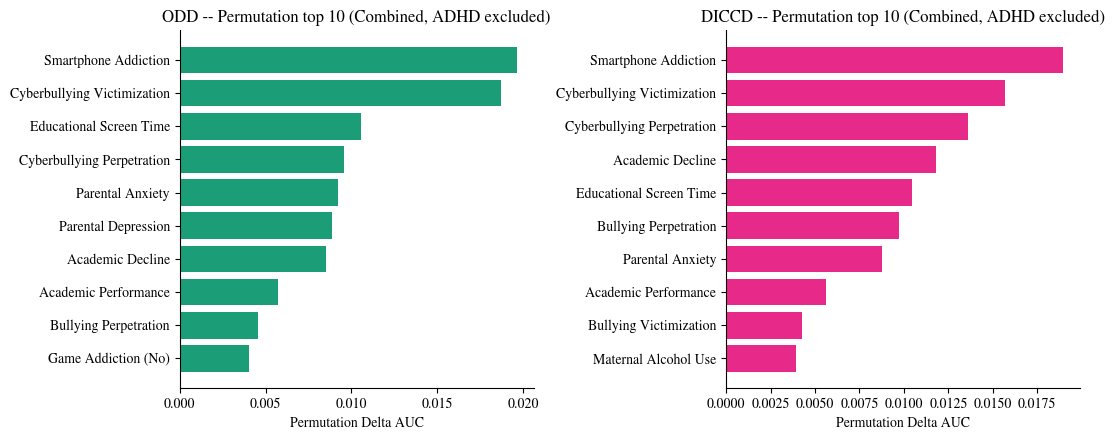

In [8]:
odd_perm = pd.read_csv(RESULTS_DIR / "permutation_odd_combined.csv").sort_values("delta_auc", ascending=False).head(10)
diccd_perm = pd.read_csv(RESULTS_DIR / "permutation_diccd_combined.csv").sort_values("delta_auc", ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, df, title, color in [
    (axes[0], odd_perm, "ODD", "#1b9e77"),
    (axes[1], diccd_perm, "DICCD", "#e7298a"),
]:
    top = df.iloc[::-1]
    ax.barh(top["label"], top["delta_auc"], color=color)
    ax.set_xlabel("Permutation Delta AUC")
    ax.set_title(f"{title} -- Permutation top 10 (Combined, ADHD excluded)")
fig.tight_layout()
plt.show()

## 5. Spearman correlation matrix -- 20 variables x ODD / DICCD (real results)

Same 20 variables used in the paper's covariate-adjusted association table (Table 3 style).
ADHD-symptom-score is included here **only as a reference point** (it is excluded from the ML
feature set above) -- it is labelled explicitly so it isn't mistaken for a modelled feature.

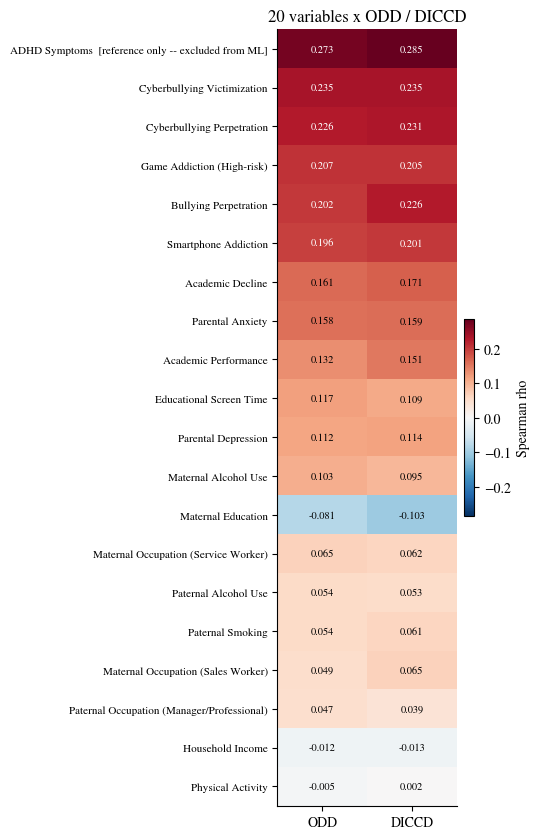

In [9]:
corr = pd.read_csv(RESULTS_DIR / "correlation_matrix_20vars.csv")
corr["variable_label"] = np.where(
    corr["variable"] == "ADHD Symptoms",
    corr["variable"] + "  [reference only -- excluded from ML]",
    corr["variable"],
)
corr_sorted = corr.reindex(corr["rho_odd"].abs().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(5.5, 8.5))
mat = corr_sorted[["rho_odd", "rho_diccd"]].to_numpy()
vmax = np.abs(mat).max()
im = ax.imshow(mat, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
ax.set_xticks([0, 1]); ax.set_xticklabels(["ODD", "DICCD"])
ax.set_yticks(range(len(corr_sorted))); ax.set_yticklabels(corr_sorted["variable_label"], fontsize=8)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{mat[i, j]:.3f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(mat[i, j]) > vmax * 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.05, pad=0.04, label="Spearman rho")
ax.set_title("20 variables x ODD / DICCD")
fig.tight_layout()
plt.show()

## Illustrative mechanism demo (synthetic, for concept only -- not a real result)

The sections above are all real results read from bundled files. The cell below is a *tiny*,
clearly-separate illustration of **one mechanism** used throughout the real pipeline --
choosing a decision threshold by the Youden index from scores/labels, then scoring a
permutation -- on a toy synthetic array, purely so the mechanism is visible in one place.
It does not use, resemble, or connect to any real number above.

In [10]:
# Synthetic toy data -- illustration only, not a result, not real data.
rng = np.random.default_rng(0)
y_toy = rng.binomial(1, 0.15, size=200)
scores_toy = np.clip(y_toy * 0.3 + rng.normal(0.3, 0.2, size=200), 0, 1)

def youden_threshold(y_true, y_score):
    """Inlined (simplified) from src/utils/models.py: threshold maximizing TPR - FPR."""
    from sklearn.metrics import roc_curve
    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    return thresholds[np.argmax(tpr - fpr)]

th_toy = youden_threshold(y_toy, scores_toy)
print(f"Illustrative Youden threshold on synthetic toy data: {th_toy:.3f} (not a real result)")

Illustrative Youden threshold on synthetic toy data: 0.349 (not a real result)


## Next steps

To re-run the real pipeline yourself (not just reproduce its results, as above): obtain data
access per [`data/README.md`](../data/README.md), place the files as documented, then use
`src/run_pipeline.py --target ODD` / `--target DICCD`.